# 04 – Choosing each kernel's setting

**Aim.** For every kernel, choose the setting (width σ or polynomial degree) that gives the best
cross-validated **balanced kNN accuracy** on the kPC scores, so that the kernels are compared fairly in
notebook 05. The chosen settings are used for the biplots there.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
X = X_raw[:, np.setdiff1d(np.arange(X_raw.shape[1]), kt.constant_columns(X_raw))]   # same as notebook 01
print("X (unscaled; scaling happens inside each fold):", X.shape)

X (unscaled; scaling happens inside each fold): (92, 51)


## 1. Method

**Why the class labels are needed.** kPCA has no built-in measure of a good setting: explained variance
cannot choose σ (a tiny σ spreads variance evenly over many kPCs, a huge σ makes the Gaussian kernel almost
linear). Our question is class discrimination, so the setting is chosen by how well the classes can be
told apart in kPC space. This is supervised calibration, as in Duma et al. (2026), who tune kernel
parameters with a discrimination objective and state that this departs from unsupervised kPCA.

**Criterion.** Balanced accuracy (mean of the per-class recalls, so the large waxing class cannot dominate)
of a k-nearest-neighbour classifier (k = 5) on the first q kPC scores. **q = 2 decides**, because the
biplots are two-dimensional; q = 3 and q = 7 are reported. The kNN uses the scores as they are, so it sees
exactly the geometry of the score plots.

**Cross-validation.** Repeated stratified 5-fold CV, 10 repeats, fixed seed → 50 test folds per setting.
Every setting uses the *same* folds, so settings are compared on identical splits. In each fold, everything
is fitted on the training samples only:
1. z-scoring (`zscore`, std with n − 1); test samples are scaled with the training mean and std,
2. σ = factor × median distance of the training samples (Gaussian, Cauchy),
3. kPCA on the training kernel matrix; test samples are projected through their kernel values against the
   training samples (centred with the training statistics),
4. kNN fitted on the training scores, evaluated on the test scores.

**Grid.** σ = median distance × 2^k, k = −4 … 4 (17 values) for Gaussian and Cauchy; degree d = 1 … 5
(γ = 1/p, c = 1) for the polynomial kernel; the linear kernel has no setting.

**Selection rule (per kernel, q = 2).** Take the best mean accuracy; its standard error is the std of the
50 fold scores / √50. Among all settings within one standard error of the best, take the *smoothest*
(largest σ, lowest degree), which is least likely to fit noise in 92 samples.

**Limitation.** Choosing a setting and reporting its score from the same CV makes that score slightly
optimistic; nested CV would remove this bias.

## 2. Cross-validation over the grid

In [2]:
Q = (2, 3, 7)
factors = 2.0 ** np.arange(-4, 5)     # sigma / median distance
degrees = [1, 2, 3, 4, 5]

GRID = {   # kernel: list of (setting label, value, arguments); listed from smoothest to least smooth
    "Linear":   [("–", None, dict(kind="linear"))],
    "Poly":     [(f"d={d}", d, dict(kind="poly", degree=d)) for d in degrees],
    "Gaussian": [(f"{f:g}", f, dict(kind="rbf", factor=f)) for f in factors[::-1]],
    "Cauchy":   [(f"{f:g}", f, dict(kind="cauchy", factor=f)) for f in factors[::-1]],
}

cv = {}   # (kernel, label) -> dict(value, scores, conf)
for kernel, settings in GRID.items():
    for label, value, args in settings:
        scores, conf = kt.cv_balanced_accuracy(X, y, **args, n_comp=Q)
        cv[(kernel, label)] = dict(value=value, scores=scores, conf=conf)
print(f"Evaluated {len(cv)} settings x 50 folds.")

def mean_se(s):
    return s.mean(), s.std(ddof=1) / np.sqrt(len(s))

Evaluated 24 settings x 50 folds.


## 3. Checks

In [3]:
# (a) polynomial d = 1 is (gamma x'y + 1): centring removes the constant and gamma only rescales the
#     scores, which kNN ignores -> must give exactly the linear kernel's results
for q in Q:
    assert np.array_equal(cv[("Poly", "d=1")]["scores"][q], cv[("Linear", "–")]["scores"][q])

# (b) every training and test fold contains all three classes
for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0).split(X, y):
    assert len(np.unique(y[tr])) == 3 and len(np.unique(y[te])) == 3

# (c) same seed -> same result
again, _ = kt.cv_balanced_accuracy(X, y, kind="rbf", factor=1.0, n_comp=Q)
assert all(np.array_equal(again[q], cv[("Gaussian", "1")]["scores"][q]) for q in Q)

print("All CV checks passed.")

All CV checks passed.


## 4. Choosing the setting for each kernel (q = 2)

In [4]:
chosen = {}
for kernel, settings in GRID.items():
    stats = [(label, *mean_se(cv[(kernel, label)]["scores"][2])) for label, _, _ in settings]
    best_mean, best_se = max(stats, key=lambda s: s[1])[1:]
    # settings are listed from smoothest to least smooth, so the first one within 1 SE is the smoothest
    label = next(l for l, m, _ in stats if m >= best_mean - best_se)
    chosen[kernel] = label
    print(f"{kernel:<9} best mean {best_mean:.3f} (SE {best_se:.3f}) -> chosen setting: {label}")

Linear    best mean 1.000 (SE 0.000) -> chosen setting: –
Poly      best mean 1.000 (SE 0.000) -> chosen setting: d=1
Gaussian  best mean 1.000 (SE 0.000) -> chosen setting: 16
Cauchy    best mean 1.000 (SE 0.000) -> chosen setting: 16


## 5. Accuracy against the setting
Mean balanced accuracy with a band of ±1 standard error, for q = 2 (decides), 3 and 7. The dashed grey line
is the linear kernel (q = 2); the ring marks the chosen setting.

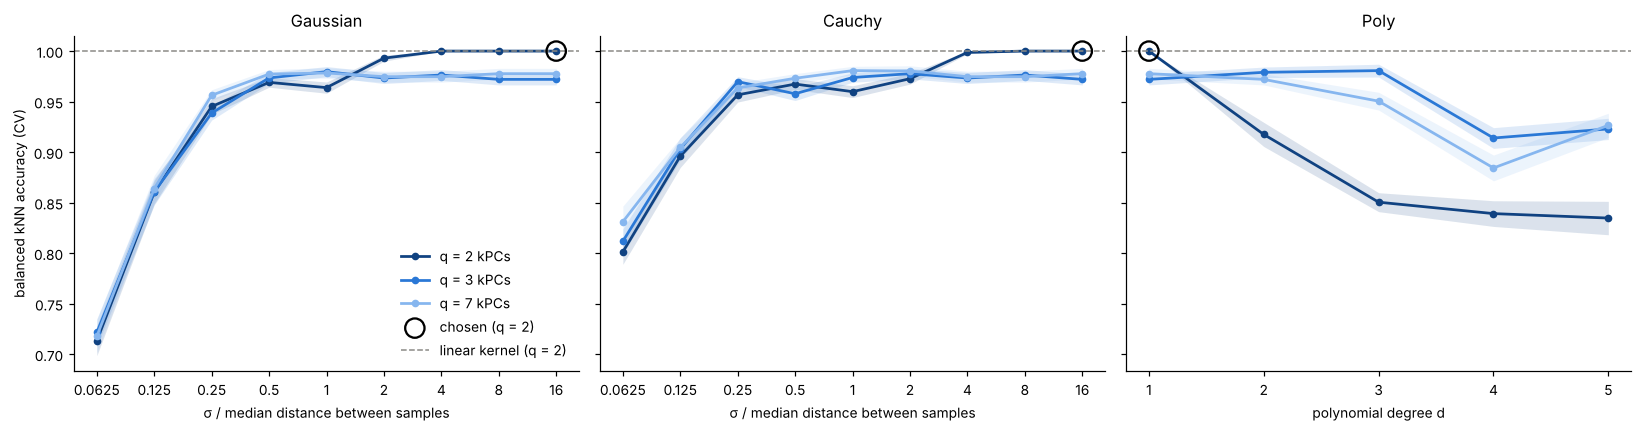

In [5]:
Q_COLORS = {2: "#104281", 3: "#2a78d6", 7: "#86b6ef"}   # one hue, darker = the q that decides
lin2 = cv[("Linear", "–")]["scores"][2].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kernel in zip(axes, ["Gaussian", "Cauchy", "Poly"]):
    settings = sorted(GRID[kernel], key=lambda s: s[1])
    x = np.array([v for _, v, _ in settings], dtype=float)
    for q in Q:
        ms = np.array([mean_se(cv[(kernel, l)]["scores"][q]) for l, _, _ in settings])
        ax.plot(x, ms[:, 0], marker="o", ms=4, lw=1.8, color=Q_COLORS[q], label=f"q = {q} kPCs")
        ax.fill_between(x, ms[:, 0] - ms[:, 1], ms[:, 0] + ms[:, 1], color=Q_COLORS[q], alpha=0.15, lw=0)
    v = cv[(kernel, chosen[kernel])]["value"]
    ax.scatter([v], [cv[(kernel, chosen[kernel])]["scores"][2].mean()], s=160, facecolor="none",
               edgecolor="k", lw=1.5, zorder=5, label="chosen (q = 2)")
    ax.axhline(lin2, color="#8b8a86", ls="--", lw=1, label="linear kernel (q = 2)")
    if kernel == "Poly":
        ax.set_xticks(x)
        ax.set_xlabel("polynomial degree d")
    else:
        ax.set_xscale("log", base=2)
        ax.set_xticks(x, [f"{f:g}" for f in x])
        ax.set_xlabel("σ / median distance between samples")
    ax.set_title(kernel)
axes[0].set_ylabel("balanced kNN accuracy (CV)")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m4_accuracy_curves.png")
plt.show()

## 6. All results (mean ± standard error over 50 test folds)

In [6]:
print(f"{'kernel':<9}{'setting':>8}" + "".join(f"{'q = ' + str(q):>17}" for q in Q))
for (kernel, label), r in cv.items():
    row = f"{kernel:<9}{label:>8}"
    for q in Q:
        m, se = mean_se(r["scores"][q])
        row += f"{m:>11.3f} ± {se:.3f}"
    print(row + ("   <- chosen" if chosen[kernel] == label else ""))

kernel    setting            q = 2            q = 3            q = 7
Linear          –      1.000 ± 0.000      0.972 ± 0.005      0.978 ± 0.005   <- chosen
Poly          d=1      1.000 ± 0.000      0.972 ± 0.005      0.978 ± 0.005   <- chosen
Poly          d=2      0.918 ± 0.012      0.979 ± 0.005      0.972 ± 0.005
Poly          d=3      0.851 ± 0.009      0.981 ± 0.006      0.950 ± 0.009
Poly          d=4      0.839 ± 0.013      0.914 ± 0.010      0.884 ± 0.013
Poly          d=5      0.835 ± 0.017      0.923 ± 0.011      0.927 ± 0.012
Gaussian       16      1.000 ± 0.000      0.972 ± 0.005      0.978 ± 0.005   <- chosen
Gaussian        8      1.000 ± 0.000      0.972 ± 0.005      0.978 ± 0.005
Gaussian        4      1.000 ± 0.000      0.976 ± 0.005      0.975 ± 0.005
Gaussian        2      0.993 ± 0.003      0.973 ± 0.005      0.975 ± 0.005
Gaussian        1      0.964 ± 0.006      0.980 ± 0.005      0.978 ± 0.005
Gaussian      0.5      0.969 ± 0.005      0.973 ± 0.005      0.977 ± 0

## 7. Chosen settings
σ on the full data set (median distance of all 92 autoscaled samples × chosen factor) is the value used
in notebook 05.

In [7]:
Z_full, _, _ = kt.zscore(X)
med_full = kt.median_distance(Z_full)

print(f"{'kernel':<9}{'setting':>10}{'sigma (full data)':>19}" + "".join(f"{'acc q=' + str(q):>10}" for q in Q))
for kernel, label in chosen.items():
    r = cv[(kernel, label)]
    sig = f"{r['value'] * med_full:.2f}" if kernel in ("Gaussian", "Cauchy") else "–"
    setting = f"x{label}" if kernel in ("Gaussian", "Cauchy") else label
    print(f"{kernel:<9}{setting:>10}{sig:>19}" + "".join(f"{r['scores'][q].mean():10.3f}" for q in Q))

kernel      setting  sigma (full data)   acc q=2   acc q=3   acc q=7
Linear            –                  –     1.000     0.972     0.978
Poly            d=1                  –     1.000     0.972     0.978
Gaussian        x16             123.95     1.000     0.972     0.978
Cauchy          x16             123.95     1.000     0.972     0.978


## 8. Which classes get mixed up?
Confusion matrices for the chosen settings (q = 2), summed over all 50 test folds (each sample is tested
10 times, once per repeat). Rows are the true class, columns the predicted class; numbers are counts and,
in brackets, the share of the true class.

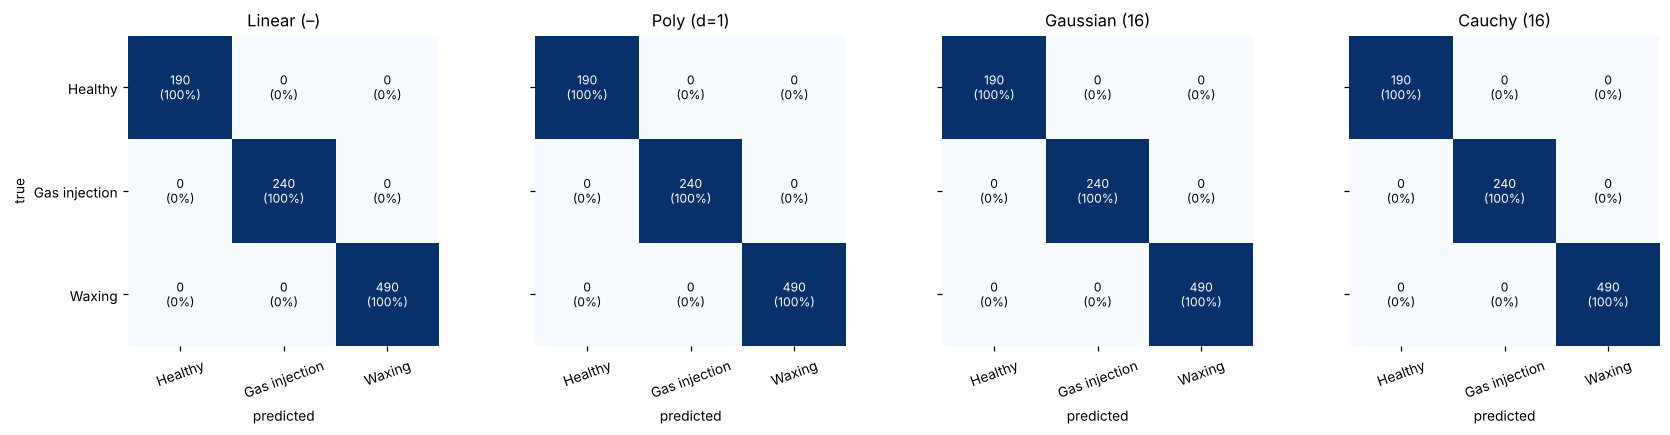

In [8]:
names = [kt.CLASS_NAMES[c] for c in kt.CLASS_NAMES]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (kernel, label) in zip(axes, chosen.items()):
    C = cv[(kernel, label)]["conf"][2]
    share = C / C.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{C[i, j]}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=8,
                    color="white" if share[i, j] > 0.6 else "black")
    ax.set_xticks(range(3), names, rotation=20)
    ax.set_yticks(range(3), names if ax is axes[0] else [])
    ax.set_xlabel("predicted")
    ax.set_title(f"{kernel} ({label})")
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("true")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m4_confusion.png")
plt.show()

## 9. How linear are the settings?
For a very large σ the Gaussian kernel becomes linear: $e^{-d^2/2\sigma^2} \approx 1 - d^2/2\sigma^2$, and
$-\lVert x-y \rVert^2/2 = x^\top y - (\lVert x \rVert^2 + \lVert y \rVert^2)/2$, whose last terms are removed by centring.
The same holds for the Cauchy kernel. To see where each setting lies, the table gives the absolute
correlation of kPC1–kPC3 (full data) with linear PC1–PC3: 1.000 means "the same as linear PCA".

In [9]:
T_lin, _, _, _ = kt.pca(Z_full)
print(f"{'kernel':<9}{'sigma/median':>13}   |corr| with linear PC1, PC2, PC3   acc q=2")
for kernel, kind in [("Gaussian", "rbf"), ("Cauchy", "cauchy")]:
    for f in factors[::-1]:
        S, _, _, _ = kt.kpca(kt.kernel_matrix(Z_full, kind, sigma=f * med_full))
        r = [abs(np.corrcoef(S[:, j], T_lin[:, j])[0, 1]) for j in range(3)]
        acc = cv[(kernel, f"{f:g}")]["scores"][2].mean()
        print(f"{kernel:<9}{f:>13g}   " + "  ".join(f"{v:.3f}" for v in r) + f"          {acc:.3f}")

kernel    sigma/median   |corr| with linear PC1, PC2, PC3   acc q=2
Gaussian            16   1.000  1.000  1.000          1.000
Gaussian             8   1.000  1.000  1.000          1.000
Gaussian             4   0.997  0.995  0.998          1.000
Gaussian             2   0.982  0.919  0.935          0.993
Gaussian             1   0.963  0.598  0.503          0.964
Gaussian           0.5   0.907  0.375  0.276          0.969
Gaussian          0.25   0.193  0.238  0.322          0.945
Gaussian         0.125   0.050  0.057  0.119          0.860
Gaussian        0.0625   0.041  0.021  0.074          0.713
Cauchy              16   1.000  1.000  1.000          1.000
Cauchy               8   0.997  0.996  0.998          1.000
Cauchy               4   0.986  0.951  0.962          0.999
Cauchy               2   0.971  0.716  0.677          0.973
Cauchy               1   0.953  0.469  0.320          0.960
Cauchy             0.5   0.906  0.354  0.365          0.967
Cauchy            0.25   0.581  

## 10. Interpretation

**Checks.** Polynomial d = 1 reproduces the linear kernel exactly in every fold, every fold contains all
three classes, and the same seed gives the same result.

**Accuracy reaches its ceiling with linear PCA.** On the first two components the linear kernel already
classifies every test sample correctly in all 50 folds (balanced accuracy 1.000). No kernel setting does
better, because none can.

**What the selection rule chooses.** Every kernel can reach 1.000 on q = 2, and the smoothest setting
that does so is chosen: σ = 16 × median distance for the Gaussian and Cauchy kernels, d = 1 for the
polynomial kernel. Section 9 shows that these settings **are linear PCA** (|corr| = 1.000 with PC1–PC3).
More generally, every setting that reaches 100 % is practically linear (|corr| ≥ 0.995). The Gaussian and
Cauchy optima also lie at the edge of the grid: a larger grid would only move them further towards the
linear limit.

**Genuinely non-linear settings lose a little accuracy on two components.** At σ around the median
distance (where kPC2 and kPC3 differ clearly from linear PC2 and PC3), the Gaussian and Cauchy kernels
reach 0.96–0.97 on q = 2. With 3 or 7 components they reach the same level as linear PCA (0.97–0.98, all
within about two standard errors of each other), so here non-linearity neither helps nor hurts.

**Small σ fails.** Below about a quarter of the median distance, accuracy drops steadily (0.71 for the
Gaussian at σ/16): each sample is then only similar to itself, and the kPCs no longer describe groups.
The heavy-tailed Cauchy kernel degrades more slowly (0.80 at σ/16), because it still "sees" distant samples.

**Polynomial kernels get worse with degree.** On q = 2, accuracy drops from 1.000 (d = 1) to 0.92 (d = 2)
and about 0.84 (d = 3–5), which matches notebook 03: higher degrees let the most extreme gas-injection
sample dominate the first kPC.

## Summary – carried into Milestone 5
- By the agreed criterion (balanced kNN accuracy), **kPCA does not improve on linear PCA** for Meter B: the
  three states are already perfectly separable in the first two linear PCs.
- The selection rule therefore returns the linear limit of every kernel. The answer to "which kernel
  discriminates best" by accuracy alone is: the linear kernel (or a Gaussian / Cauchy kernel so wide that
  it is linear); polynomial kernels of degree ≥ 2 are worse.
- Which settings to show in the notebook 05 biplots is decided before that milestone (biplots of the
  chosen settings would be identical to linear PCA).
